In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import accuracy_score, f1_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
import warnings
warnings.filterwarnings('ignore')
print('All Libraries imported Successfully')


All Libraries imported Successfully


In [15]:
df = pd.read_csv('HMAGLOFDB.csv',encoding='latin=1')

print('Dataset shape:', df.shape)
print('\nFirst 3 rows:')
print(df.head(3))

print('\All Columns name:')
for col in df.columns:
    print(' -',col)


Dataset shape: (703, 59)

First 3 rows:
   GF_ID  Year_approx  Year_exact  Month  Day Lake_name   Glacier_name  \
0      1       1533.0      1533.0    NaN  NaN       NaN   Chong Kumden   
1      2       1560.0      1560.0    NaN  NaN       NaN  Machhapuchhre   
2      3       1661.0      1661.0    NaN  NaN       NaN          Biafo   

             GL_ID LakeDB_ID            G_ID  ...  Commerical_damaged  \
0        Ephemeral       NaN  G077657E35156N  ...                 NaN   
1          No lake       NaN  G084009E28557N  ...                 NaN   
2  GL075907E35687N      2, 4  G075593E36006N  ...                 NaN   

                      Infra  Agricultural  Hydropower  Econ_damage  \
0                       NaN           NaN         NaN          NaN   
1                       NaN           NaN         NaN          NaN   
2  Entire village destroyed           NaN         NaN          NaN   

   Sat_evidence                                   Ref_scientific  \
0           NaN  (Hed

In [16]:
#printing countries in dataset
print('Countries in dataset:')
print(df['Country'].value_counts())
Pakistan_df = df[df['Country'] =='Pakistan'].copy()
print('\nPakistan Glof events:', len(Pakistan_df))
# Provinces with in PAkitan
print('\nProvinces in Pakistan data:')
print(Pakistan_df['Province'].value_counts())
#Filter Specifically for Ghanche Area
# Ghanche Coordinates: Latitiude 34.8-35.5, Longitude 75.8-77.5

Countries in dataset:
Country
China          201
Kyrgyzstan     172
Pakistan       146
India           60
Nepal           54
Kazakhstan      34
Bhutan          21
Tajikistan      11
Afghanistan      4
Name: count, dtype: int64

Pakistan Glof events: 146

Provinces in Pakistan data:
Province
Gilgit - Baltistan    137
Khyber Pakhtunkhwa      8
Chitral                 1
Name: count, dtype: int64


In [17]:
# plot glof event location for pakistan

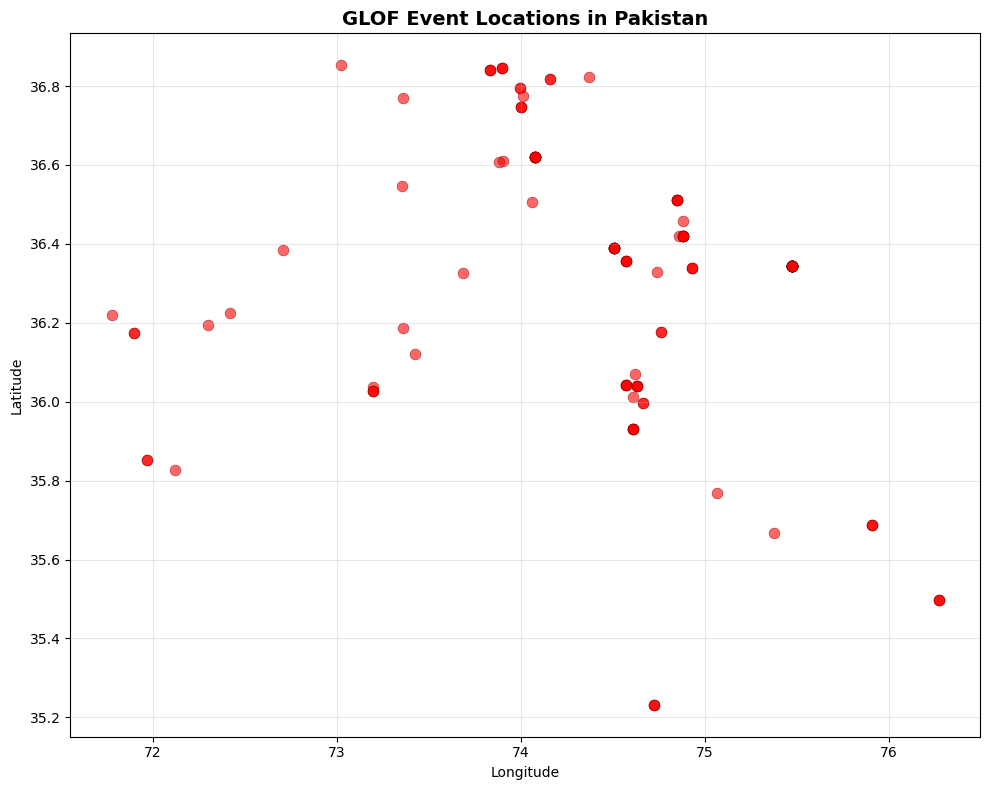

In [18]:
# Remove rows where coordinates are missing
pakistan_df_map = Pakistan_df.dropna(subset=['Lon_lake', 'Lat_lake'])

plt.figure(figsize=(10, 8))
plt.scatter(pakistan_df_map['Lon_lake'],
            pakistan_df_map['Lat_lake'],
            c='red', alpha=0.6, s=60,
            edgecolors='darkred', linewidth=0.5)
plt.title('GLOF Event Locations in Pakistan', fontsize=14, fontweight='bold')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [19]:
# Filter specifically for Ghanche / Khaplu area
# Ghanche district coordinates roughly:
# Latitude: 34.8 to 35.5
# Longitude: 75.8 to 77.0

ghanche_df = Pakistan_df[
    (Pakistan_df['Lat_lake'] >= 34.8) &
    (Pakistan_df['Lat_lake'] <= 35.5) &
    (Pakistan_df['Lon_lake'] >= 75.8) &
    (Pakistan_df['Lon_lake'] <= 77.0)
].copy()

print('GLOF events near Ghanche district:', len(ghanche_df))
print('\nGhanche area events details:')
print(ghanche_df[['Year_exact', 'Lake_type', 'Lives_total', 'Lat_lake', 'Lon_lake']])

GLOF events near Ghanche district: 3

Ghanche area events details:
     Year_exact       Lake_type Lives_total  Lat_lake  Lon_lake
342      1990.0  Moraine dammed         NaN    35.497    76.271
358      1993.0  Moraine dammed         NaN    35.497    76.271
389      2000.0  Moraine dammed         NaN    35.497    76.271


In [20]:
# check missing values
print('Missing value per column (only showing columns with gaps):')
missing = df.isnull().sum()
print(missing[missing > 0 ])
# check data types
print('\n Data Types:')
print(df.dtypes)
# checking if their any dupliactes if there is we remove it then
before = len(df)
df = df.drop_duplicates()
after = len(df)
print(f'\nRemoved {before - after} duplicates rows')
print('Final dataset shape:',df.shape)

Missing value per column (only showing columns with gaps):
Year_approx               148
Year_exact                181
Month                     375
Day                       426
Lake_name                 391
Glacier_name              293
GL_ID                     131
LakeDB_ID                 339
G_ID                       29
Elev_lake                   7
Lat_impact                241
Lon_impact                241
Elev_impact               241
Impact_type               241
Lake_type                  30
Region_RGI                  4
Region_HiMAP                4
Province                  216
River_Basin                46
Driver_lake               562
Driver_GLOF               616
Mechanism                 520
Area                      669
Volume                    598
Discharge_water           631
Discharge_solid           684
Impact                    679
Lives_total               673
Lives_male                702
Lives_female              701
Lives_disabilities        703
Injured_tot

In [21]:
# Work with a Clean Copy
df_model = df.copy()
# select useful columns using correct columns names
useful_cols = ['Country','Year_exact','Month','Lake_type','Driver_GLOF','Lives_total','Lat_lake','Lon_lake']
# checking which columns exist in our dataset
existing_cols = [col for col in useful_cols if col in df_model.columns]
print('Columns we will use:', existing_cols)
df_model = df_model[existing_cols].copy()
df_model = df_model.dropna(subset=['Lives_total'])
for col in ['Year_exact', 'Month','Lat_lake','Lon_lake']:
    if col in df_model.columns:
        df_model[col].fillna(df_model[col].median(), inplace=True)
#Fill missing text with unknown
for col in ['Lake type','Driver_GLOF','Country']:
    if col in df_model.columns:
        df_model[col].fillna('df_model[col].median(), inplace=True')
# Fill missing txt with unknown
for col in ['Lake type','Driver_GLOF','Country']:
    if col in df_model.columns:
        df_model[col].fillna('Unknown', inplace=True)
print('Shape after cleaning:',df_model.shape)
print('Missing values remaining:',df_model.isnull().sum().sum())
    

Columns we will use: ['Country', 'Year_exact', 'Month', 'Lake_type', 'Driver_GLOF', 'Lives_total', 'Lat_lake', 'Lon_lake']
Shape after cleaning: (30, 8)
Missing values remaining: 1


In [22]:
#creating target label from lives total 
#1 or more deaths = high fatality (1)
#0 deaths = low fatality (0)

In [23]:
# Convert Lives_total to numbers first
df_model['Lives_total'] = pd.to_numeric(df_model['Lives_total'], errors='coerce')
df_model['Lives_total'] = df_model['Lives_total'].fillna(0)

# Now create target label
df_model['HighFatality'] = (df_model['Lives_total'] > 0).astype(int)

print('Fatality label distribution:')
print(df_model['HighFatality'].value_counts())
print('\nPercentage:')
print(df_model['HighFatality'].value_counts(normalize=True) * 100)

# Add Season feature from Month
def get_season(month):
    if month in [12, 1, 2]: return 'Winter'
    elif month in [3, 4, 5]: return 'Spring'
    elif month in [6, 7, 8]: return 'Summer'
    else: return 'Autumn'

if 'Month' in df_model.columns:
    df_model['Season'] = df_model['Month'].apply(get_season)
    print('\nSeason distribution:')
    print(df_model['Season'].value_counts())

Fatality label distribution:
HighFatality
1    26
0     4
Name: count, dtype: int64

Percentage:
HighFatality
1    86.666667
0    13.333333
Name: proportion, dtype: float64

Season distribution:
Season
Summer    25
Autumn     4
Spring     1
Name: count, dtype: int64


In [24]:
# Converting the Text Columns to Numbers
#

In [25]:
le = LabelEncoder()
text_cols = ['Country', ' Lake_type','Driver_GLOF','Season']
for col in text_cols:
    if col in df_model.columns:
        df_model[col + '_encoded'] = le.fit_transform(df_model[col].astype(str))
print(f'{col} encoded succesfully')

print('\nDataset after encoding:')
print(df_model.head(3))
        

Season encoded succesfully

Dataset after encoding:
        Country  Year_exact  Month       Lake_type  Driver_GLOF  Lives_total  \
66   Tajikistan      1910.0    7.0  Moraine dammed      Unknown          0.0   
139       China      1954.0    7.0  Moraine dammed  Ice calving        400.0   
181  Kazakhstan      1963.0    7.0  Moraine dammed      Unknown         52.0   

      Lat_lake   Lon_lake  HighFatality  Season  Country_encoded  \
66   38.690000  72.090000             0  Summer                8   
139  28.238799  90.109247             1  Summer                2   
181  43.152000  77.408000             1  Summer                4   

     Driver_GLOF_encoded  Season_encoded  
66                     8               2  
139                    3               2  
181                    8               2  


In [26]:
#now removing rows with missing coordinates

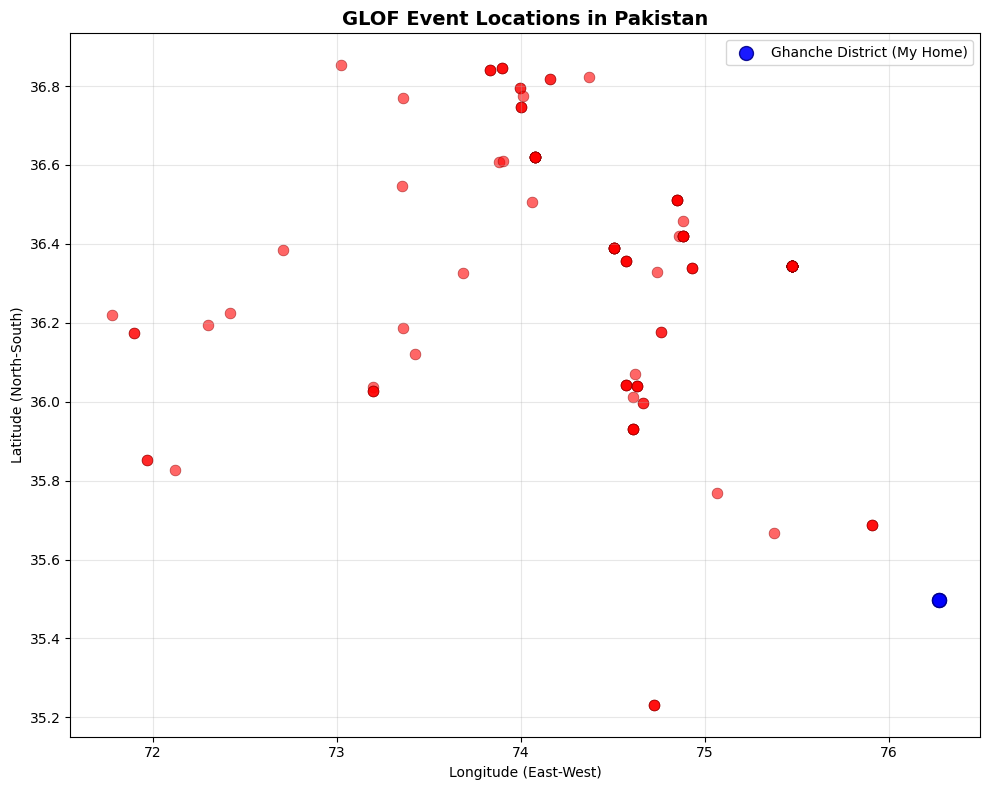

In [27]:
# Remove rows with missing coordinates
pakistan_df_map = Pakistan_df.dropna(subset=['Lon_lake', 'Lat_lake'])

# Map of Pakistan GLOF Locations
plt.figure(figsize=(10, 8))
plt.scatter(pakistan_df_map['Lon_lake'],
            pakistan_df_map['Lat_lake'],
            c='red', alpha=0.6, s=60,
            edgecolors='darkred', linewidth=0.5)

# Mark Ghanche area specifically
ghanche_map = pakistan_df_map[
    (pakistan_df_map['Lat_lake'] >= 34.8) &
    (pakistan_df_map['Lat_lake'] <= 35.5) &
    (pakistan_df_map['Lon_lake'] >= 75.8) &
    (pakistan_df_map['Lon_lake'] <= 77.5)
]

plt.scatter(ghanche_map['Lon_lake'],
            ghanche_map['Lat_lake'],
            c='blue', alpha=0.9, s=100,
            edgecolors='darkblue', linewidth=1,
            label='Ghanche District (My Home)')

plt.title('GLOF Event Locations in Pakistan', fontsize=14, fontweight='bold')
plt.xlabel('Longitude (East-West)')
plt.ylabel('Latitude (North-South)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [28]:
#Glof over time

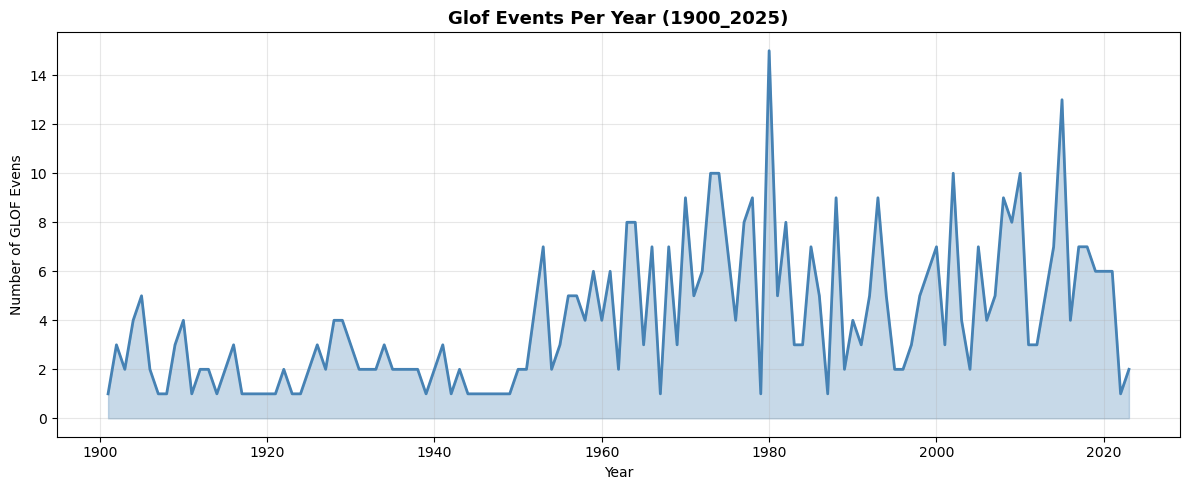

In [29]:
plt.figure(figsize=(12,5))
yearly = df.groupby('Year_exact').size()
yearly = yearly[yearly.index>1900]
plt.plot(yearly.index,yearly.values,color='steelblue',linewidth=2)
plt.fill_between(yearly.index, yearly.values,alpha=0.3,color='steelblue')
plt.title('Glof Events Per Year (1900_2025)', fontsize=13, fontweight='bold')
plt.xlabel('Year')
plt.ylabel('Number of GLOF Evens')
plt.grid(True,alpha=0.3)
plt.tight_layout()
plt.show()

# What Causes GLOF EVENTs

In [30]:
plt.figure(figsize=(10,6))

<Figure size 1000x600 with 0 Axes>

<Figure size 1000x600 with 0 Axes>

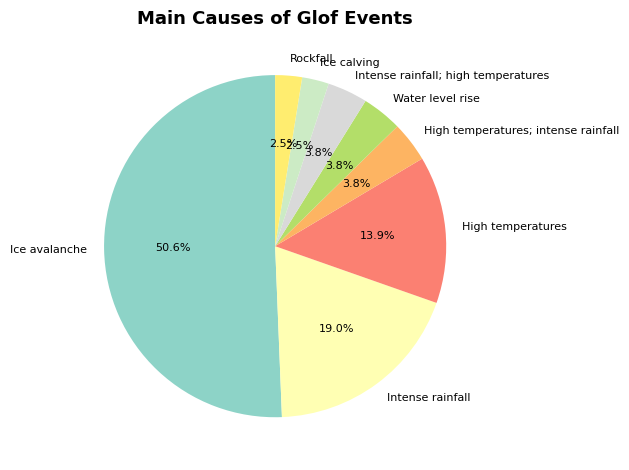

In [31]:
if 'Driver_GLOF' in df.columns:
    cause_counts = df['Driver_GLOF'].value_counts().head(8)
    colors = plt.cm.Set3(np.linspace(0,1, len(cause_counts)))
    plt.pie(cause_counts.values,
            labels=cause_counts.index,
            colors=colors,
             textprops={'fontsize': 8},
            autopct='%1.1f%%',
            startangle=90)
    plt.title('Main Causes of Glof Events',fontsize=13,
    fontweight='bold')
    plt.tight_layout()

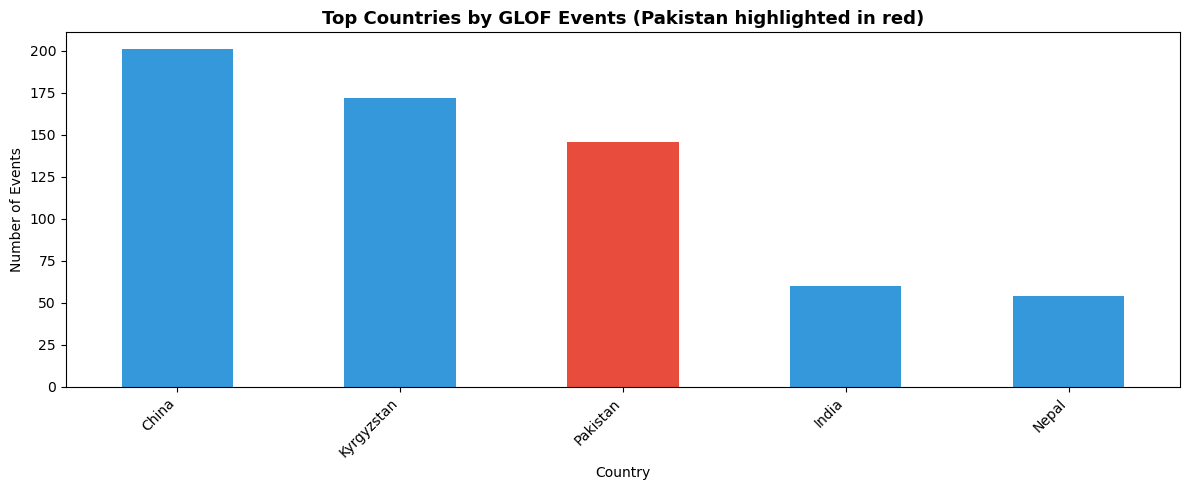

In [32]:
#Top Countries by GLOF Events
plt.figure(figsize=(12,5))
country_counts = df['Country'].value_counts().head()
colors = ['#E74C3C' if c == 'Pakistan' else '#3498DB'
          for c in country_counts.index]
country_counts.plot(kind='bar',color=colors)
plt.title('Top Countries by GLOF Events (Pakistan highlighted in red)',fontsize=13,fontweight='bold')
plt.xlabel('Country')
plt.ylabel('Number of Events')
plt.xticks(rotation=45,ha='right')
plt.tight_layout()
plt.show()


In [33]:
# Selecting Feature columns 
feature_cols = []
# Add Encoded text features
for col in ['Country_encoded','Lake_type_encoded',
            'Driver_GLOF_encoder','Season_encoder']:
    if col in df_model.columns:
        feature_cols.append(col)
# Now Adding numeric features
for col in ['Year_exact','Month','Lat_lake','Lon_lake']:
    if col in df_model.columns:
        feature_cols.append(col)
print('Features we will use:', feature_cols)

X = df_model[feature_cols]
y = df_model['HighFatality']

print('Features shape:', X.shape)
print('Target distribution:')
print(y.value_counts())

#Split _ use stratify to keep balance
#Remove Stratify = y if u get an error
try:
    X_train,X_test,y_train,y_test = train_test_split(
        X,y,test_size=0.2,random_state=42,stratify=y)
except:
    X_train,X_test,y_train,y_test = train_test_split(
        X,y,test_size=0.2,random_state=42)
# Scale Features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Training size :',X_train.shape)
print('Testing size:',X_test.shape)
                                                     
                                                    
                                                    

Features we will use: ['Country_encoded', 'Year_exact', 'Month', 'Lat_lake', 'Lon_lake']
Features shape: (30, 5)
Target distribution:
HighFatality
1    26
0     4
Name: count, dtype: int64
Training size : (24, 5)
Testing size: (6, 5)


# Training Three Models

In [34]:
#Train Model 1 - Random Forest

In [35]:
rf_model = RandomForestClassifier(
    random_state=42, 
    class_weight={0: 10, 1: 1},  # Gives '0' (Low Fatality) 10x more importance!
    max_depth=3,                 # Simplifies the model so it can't overfit
    min_samples_leaf=2)        # Prevents it from ignoring small groups
rf_model.fit(X_train_scaled,y_train)
rf_pred= rf_model.predict(X_test_scaled)
print('Random Forest Trained')

Random Forest Trained


In [36]:
# Our 2nd Model - Gradient Boosting
gb_model = GradientBoostingClassifier(n_estimators=100, random_state=42,)
gb_model.fit(X_train_scaled, y_train)
gb_pred = gb_model.predict(X_test_scaled)
print('Gradient Boosting Trained')

Gradient Boosting Trained


In [37]:
# Our 3rd Model _ Decison Tree
dt_model = DecisionTreeClassifier(max_depth=8,random_state=42, class_weight='balanced')
dt_model.fit(X_train_scaled,y_train)
dt_pred = dt_model.predict(X_test_scaled)
print('Decision Tree Classifier')


Decision Tree Classifier


# Compare All three Models

In [38]:
models = {
    'Random Forest' : (rf_model, rf_pred),
    'Gradient Boosting' : (gb_model, gb_pred),
    'Decision Tree':(dt_model,dt_pred)
}

print('=' * 55)
print('MODEL COMPARISON RESULTS')
print('=' * 55 )
for name, (model,pred) in models.items():
    acc =  accuracy_score(y_test,pred)
    f1 = f1_score(y_test,pred,zero_division=0)
    print(f'{name}:')
    print(f' Accuracy : {acc*100:.1f}%')
    print(f' F1 Score: {f1:.3f}')
    print()
print('=' * 55)

# Detailed report for best model
print('\nDetailed Report - Random Forest:')
print(classification_report(y_test,rf_pred,
                            target_names=['Low Fatality','High Fatality'],
                            zero_division=0))
                            
                        

MODEL COMPARISON RESULTS
Random Forest:
 Accuracy : 66.7%
 F1 Score: 0.800

Gradient Boosting:
 Accuracy : 66.7%
 F1 Score: 0.800

Decision Tree:
 Accuracy : 50.0%
 F1 Score: 0.667


Detailed Report - Random Forest:
               precision    recall  f1-score   support

 Low Fatality       0.00      0.00      0.00         1
High Fatality       0.80      0.80      0.80         5

     accuracy                           0.67         6
    macro avg       0.40      0.40      0.40         6
 weighted avg       0.67      0.67      0.67         6



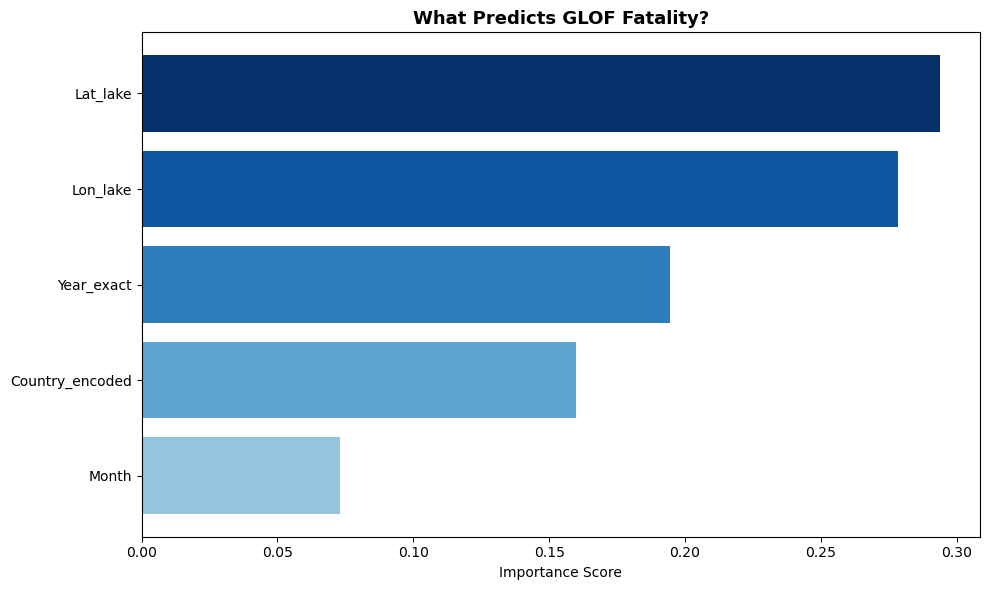


Top 5 most Important Factors:
           Feature  Importance
3         Lat_lake    0.293860
4         Lon_lake    0.278369
1       Year_exact    0.194621
0  Country_encoded    0.159972
2            Month    0.073178


In [39]:
# Feature importance - what predict GLOF fatality?
importances = rf_model.feature_importances_
importances_df = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': importances
})
importance_df = importances_df.sort_values('Importance', ascending=False)

plt.figure(figsize=(10,6))
colors = plt.cm.Blues(np.linspace(0.4,1,len(importance_df)))
plt.barh(importance_df['Feature'],
         importance_df['Importance'],
         color=colors[::-1])
plt.title('What Predicts GLOF Fatality?',
          fontsize=13,fontweight='bold')
plt.xlabel('Importance Score')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()
print('\nTop 5 most Important Factors:')
print(importance_df.head())


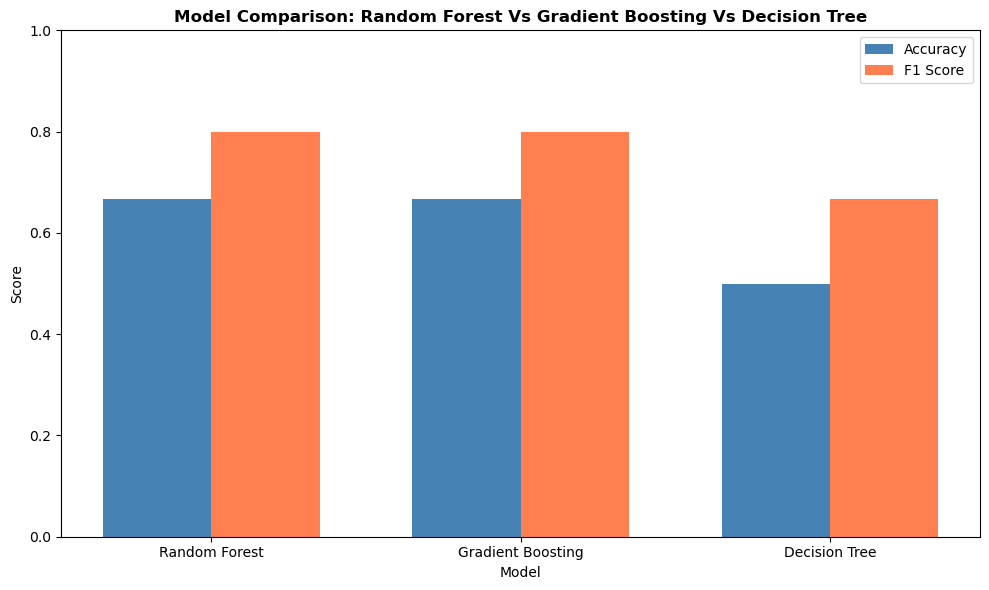

In [42]:
# Final Comparison Chart
model_names = list(models.keys())
accuracies = [accuracy_score(y_test,pred) for _, pred in
models.values()]
f1_scores_list = [f1_score(y_test, pred,zero_division = 0) for _, pred in 
models.values()]

x = range (len(model_names))
width = 0.35
plt.figure (figsize = (10, 6))
plt.bar([i - width/2 for i in x], accuracies,
        width, label='Accuracy', color='steelblue')
plt.bar([i + width/2 for i in x], f1_scores_list,
        width, label='F1 Score', color='coral')
plt.xlabel('Model')
plt.ylabel('Score')
plt.title('Model Comparison: Random Forest Vs Gradient Boosting Vs Decision Tree',
        fontsize=12, fontweight='bold')
plt.xticks(x, model_names)
plt.ylim(0 ,1.0)
plt.legend()
plt.tight_layout()
plt.show()